
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

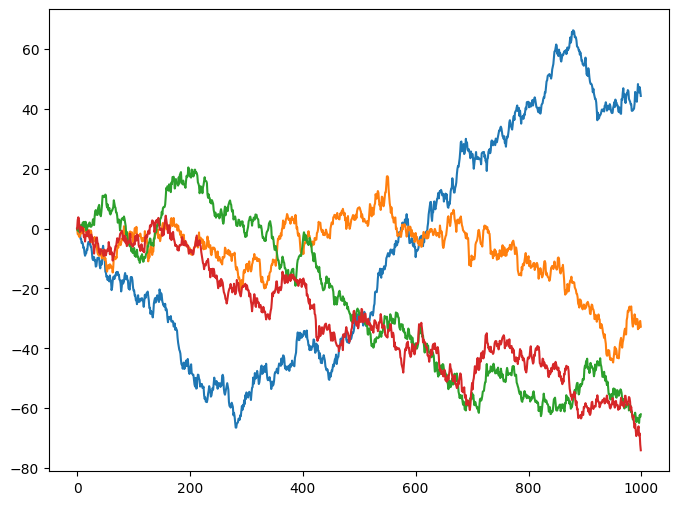

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import multivariate_normal
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

#primero sin fuerza externa tenemos lo siguiente:

def mov_browniano(delta_t,xi,D,tf):
  x=xi
  X=np.zeros(tf)
  X[0]=xi
  for i in range (1,tf):
    Z=np.random.normal()
    x=x+np.sqrt(2*D*delta_t)*Z
    X[i]=x
  return X

X1=mov_browniano(1,0,1,1000)
X2=mov_browniano(1,0,1,1000)
X3=mov_browniano(1,0,1,1000)
X4=mov_browniano(1,0,1,1000)

plt.figure(figsize=(8,6))
plt.plot(X1)
plt.plot(X2)
plt.plot(X3)
plt.plot(X4)

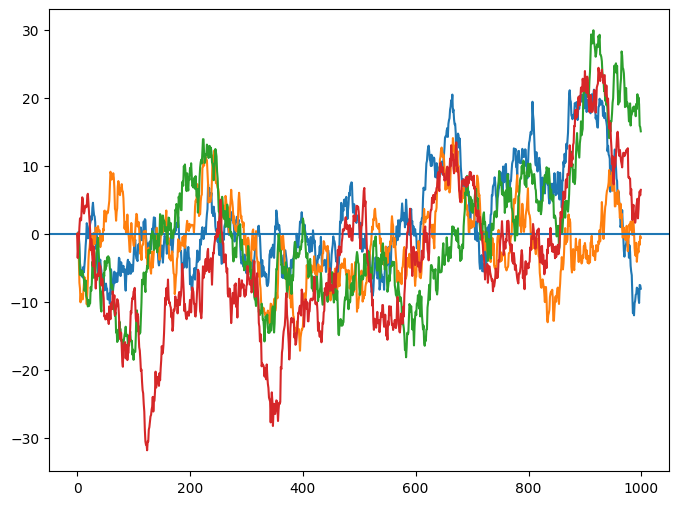

In [3]:
#ahora le voy a agregar la fuerza externa


def mov_browniano_fuerza(delta_t,xi,D,tf,k,gamma):
  x=xi
  X=np.zeros(tf)
  X[0]=xi
  for i in range (1,tf):
    Z=np.random.normal()
    x=x+-(k/gamma)*x*delta_t+np.sqrt(2*D*delta_t)*Z
    X[i]=x
  return X


k=0.001
gamma=0.1
tf=1000
delta_t=1
ti=0
D=1
tf=1000

X1=mov_browniano_fuerza(delta_t,ti,D,tf,k,gamma)
X2=mov_browniano_fuerza(delta_t,ti,D,tf,k,gamma)
X3=mov_browniano_fuerza(delta_t,ti,D,tf,k,gamma)
X4=mov_browniano_fuerza(delta_t,ti,D,tf,k,gamma)

plt.figure(figsize=(8,6))
plt.plot(X1)
plt.plot(X2)
plt.axhline(y=0)
plt.plot(X3)
plt.plot(X4)

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )

def score(x):
    return -(x - mu) / varianza



In [5]:
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x = np.zeros((n_trayectorias, n_pasos))
np.shape(x)
t = np.arange(n_pasos+1 ) * dt

In [6]:
x = np.zeros((n_trayectorias, n_pasos + 1))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

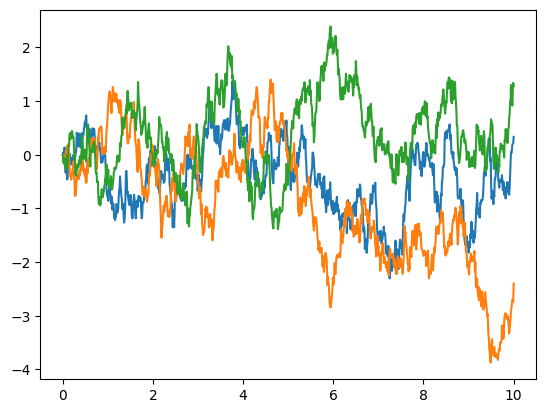

In [7]:
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])

In [8]:
x=np.concat(x)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


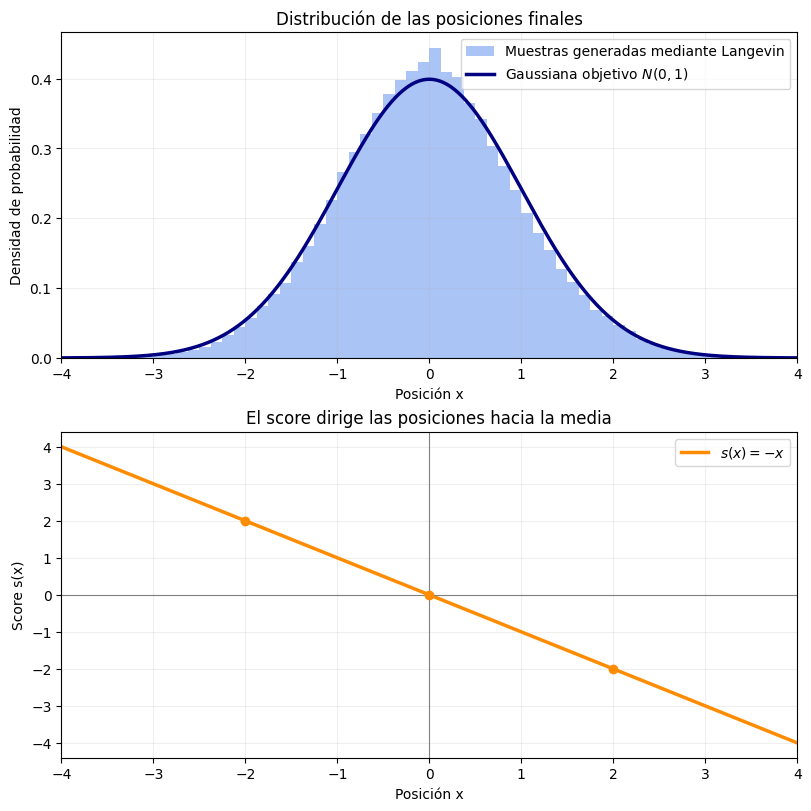

In [9]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

Media final: [ 0.014 -0.007]
Covarianza final:
 [[ 0.958 -0.016]
 [-0.016  1.012]]


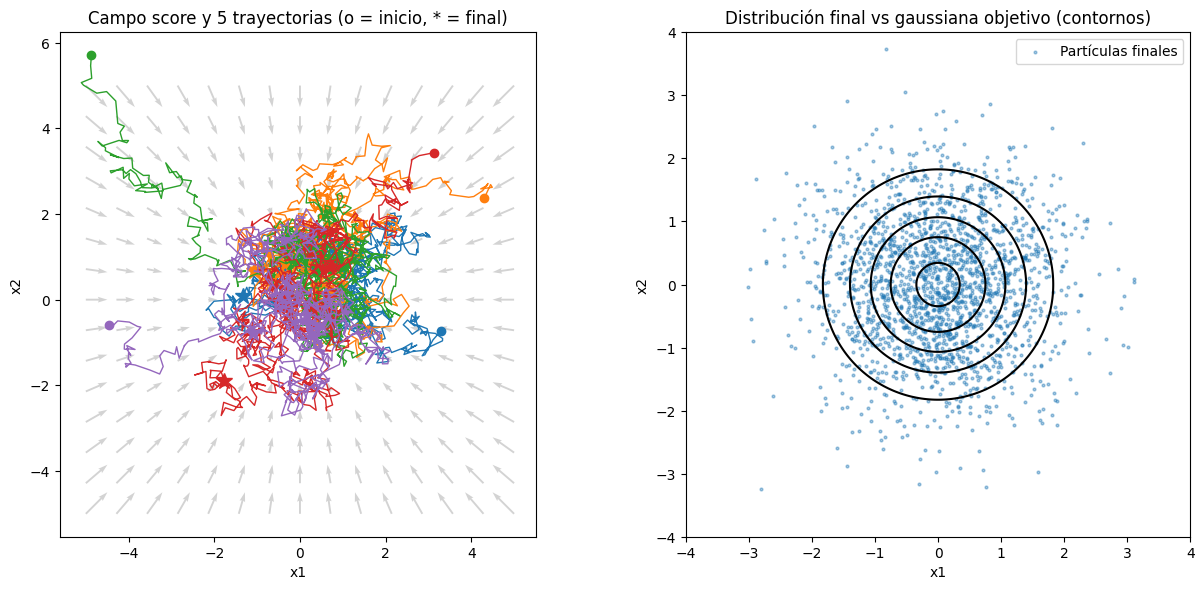

In [10]:
#AHORA LA PARTET DE LA DINAMICA DE LANGEVIN
from scipy.stats import multivariate_normal

rng = np.random.default_rng(42)

# Score de la gaussiana 2D: media (0,0), covarianza identidad -> s(x) = -x
mu = np.array([0.0, 0.0])
def score(x):                       # x tiene forma (n, 2)
    return -(x - mu)

n_part = 2000
n_pasos = 1000
dt = 0.01                           # tiempo total = 10

# Partículas iniciales al azar en el plano (uniforme en [-6, 6] x [-6, 6])
x = rng.uniform(-6, 6, size=(n_part, 2))
x_inicial = x.copy()

# Guardamos solo 5 trayectorias completas
tray = np.zeros((n_pasos + 1, 5, 2))
tray[0] = x[:5]

# Euler-Maruyama con D = 1:  x <- x + s(x) dt + sqrt(2 dt) * eps
for j in range(n_pasos):
    eps = rng.normal(size=(n_part, 2))
    x = x + dt * score(x) + np.sqrt(2 * dt) * eps
    tray[j + 1] = x[:5]

# Media y covarianza de las posiciones FINALES
media = x.mean(axis=0)
cov = np.cov(x.T)
print("Media final:", np.round(media, 3))
print("Covarianza final:\n", np.round(cov, 3))

# Gráficas
fig, axs = plt.subplots(1, 2, figsize=(13, 6))

# (a) Campo score y 5 trayectorias
g = np.linspace(-5, 5, 15)
GX, GY = np.meshgrid(g, g)
S = score(np.column_stack([GX.ravel(), GY.ravel()]))
axs[0].quiver(GX, GY, S[:, 0].reshape(GX.shape), S[:, 1].reshape(GX.shape), color="lightgray")
for k in range(5):
    axs[0].plot(tray[:, k, 0], tray[:, k, 1], lw=1, color=f"C{k}")
    axs[0].plot(*tray[0, k], "o", color=f"C{k}")      # inicio
    axs[0].plot(*tray[-1, k], "*", color=f"C{k}", markersize=12)  # final
axs[0].set_title("Campo score y 5 trayectorias (o = inicio, * = final)")
axs[0].set_xlabel("x1"); axs[0].set_ylabel("x2"); axs[0].set_aspect("equal")

# (b) Partículas finales vs gaussiana objetivo
axs[1].scatter(x[:, 0], x[:, 1], s=4, alpha=0.4, label="Partículas finales")
gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
pdf = multivariate_normal(mu, np.eye(2)).pdf(np.dstack([gx, gy]))
axs[1].contour(gx, gy, pdf, colors="k", levels=5)
axs[1].set_title("Distribución final vs gaussiana objetivo (contornos)")
axs[1].set_xlabel("x1"); axs[1].set_ylabel("x2")
axs[1].set_xlim(-4, 4); axs[1].set_ylim(-4, 4); axs[1].set_aspect("equal")
axs[1].legend()

plt.tight_layout()
plt.show()